# 01 — Data quality and exploratory checks

**Goal.** Before any modelling, find out what is odd in the raw file and decide what to do about
each oddity. Every decision taken here is recorded in `docs/DECISIONS.md` (ADR-008 and ADR-009).

**What this notebook covers**

1. Target rate and missing values
2. Category codes that are not in the dataset documentation
3. Repayment-status codes (`PAY_*`): what they are, what they seem to mean, and why the September
   status needs care
4. Negative balances, balances above the credit limit and inactive accounts
5. Identical rows
6. Extreme values
7. Which statement a payment settles (payment timing)
8. The fixed recoding applied to the data
9. Which columns are available at prediction time

**What it deliberately does not cover.** The train/test split has not been made yet, so looking at
default rates by feature here would mean looking at rows that will later form the test set. The
target is used in two places only: the overall default rate, and the count of identical rows.
Feature-versus-target analysis is done in the binning notebook, on training data only.

All the checks are functions in `creditrisk.data.quality`; this notebook calls them and explains
the results. The numbers are saved to `reports/metrics/data_quality.json` at the end.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from creditrisk import plotting
from creditrisk.data import clean, quality
from creditrisk.data.load import load_project_data
from creditrisk.data.schema import (
    BILL_COLS,
    CANDIDATE_FEATURE_COLS,
    DOCUMENTED_CODES,
    MONTH_LABELS,
    PAY_COLS,
    PAYAMT_COLS,
    SENSITIVE_COLS,
    TARGET,
)
from creditrisk.reporting import save_metrics

plotting.apply_style()
pd.set_option("display.max_columns", 30)


def show(table, percent=(), whole=()):
    """Display a table with shares written as percentages and counts with thousands separators."""
    out = table.copy()
    for column in percent:
        out[column] = out[column].map("{:.1%}".format, na_action="ignore")
    for column in whole:
        out[column] = out[column].map("{:,.0f}".format)
    display(out)

## Load the raw file

`load_project_data` checks the SHA-256 of the file against `config/project.yaml` and validates the
schema, so everything below is known to run on the exact file described in `docs/DATA.md`.

Column convention: month 1 = September 2005 (most recent) … month 6 = April 2005. The target is
default in October 2005. The raw file also has an `ID` column, a row number from 1 to 30,000 that
the loader drops; it is not documented as a client key.

In [2]:
raw, data_sha256 = load_project_data()
print(f"SHA-256: {data_sha256}")
print(f"Shape:   {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

SHA-256: 30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369220bd60cfc82700933
Shape:   30,000 rows x 24 columns


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 1. Target rate and missing values

The loader fails if the file does not have 30,000 rows and 6,636 defaults, the counts of the file
this project is built on. They are shown here for the record.

In [3]:
target = quality.target_summary(raw)
missing = quality.missing_counts(raw)

print(f"Rows:           {target['n_rows']:,}")
print(f"Defaults:       {target['n_defaults']:,}")
print(f"Default rate:   {target['default_rate']:.2%}")
print(f"Missing values: {sum(missing.values())} (all columns together)")

Rows:           30,000
Defaults:       6,636
Default rate:   22.12%
Missing values: 0 (all columns together)


There are no missing values stored as nulls. That does not mean the data is complete: as the next
sections show, "unknown" is hidden inside undocumented category codes.

The file does not say how "default" was defined or how the clients were sampled, so the default
rate is taken as given and is not read as the default rate of the bank's whole portfolio.

## 2. Category codes outside the documentation

The documentation lists `SEX` 1–2, `EDUCATION` 1–4 (4 = others) and `MARRIAGE` 1–3 (3 = others).

In [4]:
for column in ["SEX", "EDUCATION", "MARRIAGE"]:
    table = quality.code_counts(raw, column, DOCUMENTED_CODES[column])
    undocumented = table.loc[~table["documented"], "count"].sum()
    print(
        f"{column}: {undocumented:,} rows with an undocumented code "
        f"({undocumented / len(raw):.2%} of the file)"
    )
    show(table.set_index("value"), percent=["share"], whole=["count"])

SEX: 0 rows with an undocumented code (0.00% of the file)


,count,share,documented
value,,,
1,"11,888",39.6%,True
2,"18,112",60.4%,True


EDUCATION: 345 rows with an undocumented code (1.15% of the file)


,count,share,documented
value,,,
0,14,0.0%,False
1,"10,585",35.3%,True
2,"14,030",46.8%,True
3,"4,917",16.4%,True
4,123,0.4%,True
5,280,0.9%,False
6,51,0.2%,False


MARRIAGE: 54 rows with an undocumented code (0.18% of the file)


,count,share,documented
value,,,
0,54,0.2%,False
1,"13,659",45.5%,True
2,"15,964",53.2%,True
3,323,1.1%,True


`EDUCATION` has three undocumented codes (0, 5, 6) and `MARRIAGE` has one (0). `SEX` is clean.

**Decision (ADR-008).** The undocumented codes are moved into the documented "others" category
(`EDUCATION` → 4, `MARRIAGE` → 3). Nothing in the documentation tells these codes apart, they are a
small share of the file, and "others" is the only documented category that does not claim to know
what they mean. The decision is taken without looking at their default rates.

## 3. Repayment-status codes

The documentation describes `PAY_*` as −1 = paid duly and 1–9 = months of payment delay. The table
counts accounts per code and month.

In [5]:
pay_counts = quality.pay_code_counts(raw)
show(pay_counts, whole=PAY_COLS)
print(
    f"Share of account-months with an undocumented code: {quality.undocumented_pay_share(raw):.1%}"
)

,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,documented
code,,,,,,,
-2,"2,759","3,782","4,085","4,348","4,546","4,895",False
-1,"5,686","6,050","5,938","5,687","5,539","5,740",True
0,"14,737","15,730","15,764","16,455","16,947","16,286",False
1,"3,688",28,4,2,0,0,True
2,"2,667","3,927","3,819","3,159","2,626","2,766",True
3,322,326,240,180,178,184,True
4,76,99,76,69,84,49,True
5,26,25,21,35,17,13,True
6,11,12,23,5,4,19,True


Share of account-months with an undocumented code: 66.9%


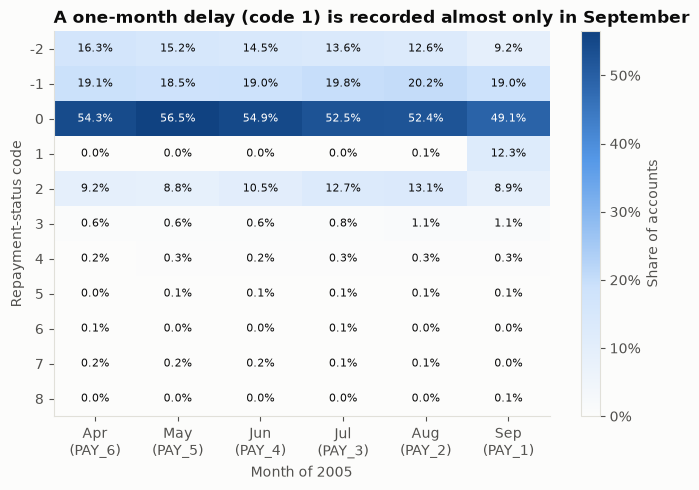

In [6]:
# Months in calendar order (April -> September) so the chart reads left to right in time.
months = sorted(MONTH_LABELS, reverse=True)
shares = pay_counts[[f"PAY_{k}" for k in months]] / len(raw)

fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(shares.to_numpy(), cmap=plotting.SEQUENTIAL, aspect="auto", vmin=0)
ax.set_xticks(range(len(months)), [f"{MONTH_LABELS[k]}\n(PAY_{k})" for k in months])
ax.set_yticks(range(len(shares)), shares.index)
ax.set_xlabel("Month of 2005")
ax.set_ylabel("Repayment-status code")
ax.grid(False)
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        value = shares.iat[i, j]
        colour = "white" if value > 0.3 else plotting.INK
        ax.text(j, i, f"{value:.1%}", ha="center", va="center", fontsize=8, color=colour)
fig.colorbar(image, ax=ax, label="Share of accounts", format=lambda x, _: f"{x:.0%}")
ax.set_title("A one-month delay (code 1) is recorded almost only in September")
plotting.save_figure(fig, "eda_pay_code_shares")
plt.show()

Three things stand out.

- **About two thirds of account-months carry an undocumented code.** Codes −2 and 0 are not in the
  documentation, yet 0 alone is the most common value in every month.
- **Code 1 is nearly absent outside September.** A one-month delay is recorded 3,688 times in
  `PAY_1` and at most 28 times in any earlier month, while a two-month delay is common in every
  month. September seems to be recorded on a different basis from the earlier months. The file does
  not explain why.
- **Code 9 never appears**, although it is documented.

### What do the codes mean?

Codes −2 and 0 are commonly read as "no consumption" and "revolving credit" (the minimum was paid,
the balance was not cleared). That reading has no documentation behind it and no citation is
given for it here. It can be checked against the bills and payments, but first we need to know
*which* bill and *which* payment the status of a month refers to. The file does not say, so two
pairings are compared on the months where both can be computed (May to August):

- **following month:** the statement of month *k* and the payment made the month after;
- **same month:** the statement of the month before and the payment made in month *k*.

For each code the table gives the number of account-months, the share with nothing to pay
(statement zero or negative), the share with no payment, and, among those with something to pay,
the share that paid it in full.

In [7]:
shared_months = [2, 3, 4, 5]  # August ... May: the months where both pairings exist
share_columns = ["share_statement_not_positive", "share_no_payment", "share_paid_in_full"]

for pairing in ["following_month", "same_month"]:
    print(f"Pairing: {pairing} (months {shared_months})")
    show(
        quality.pay_status_profile(raw, pairing, shared_months), percent=share_columns, whole=["n"]
    )

Pairing: following_month (months [2, 3, 4, 5])


,n,share_statement_not_positive,share_no_payment,share_paid_in_full
code,,,,
-2,"16,761",63.4%,61.7%,93.5%
-1,"23,214",10.5%,10.1%,98.4%
0,"64,896",2.0%,3.9%,0.2%
1,34,61.8%,29.4%,0.0%
2,"13,531",2.5%,48.2%,0.3%
3,924,0.0%,76.2%,0.2%
4,328,0.0%,77.4%,0.0%
5,98,0.0%,84.7%,0.0%
6,44,0.0%,95.5%,0.0%


Pairing: same_month (months [2, 3, 4, 5])


,n,share_statement_not_positive,share_no_payment,share_paid_in_full
code,,,,
-2,"16,761",56.4%,55.1%,95.3%
-1,"23,214",15.6%,22.2%,75.8%
0,"64,896",4.1%,8.0%,5.1%
1,34,35.3%,35.3%,40.9%
2,"13,531",3.8%,27.8%,7.2%
3,924,0.0%,60.8%,0.2%
4,328,0.0%,81.1%,0.0%
5,98,0.0%,86.7%,0.0%
6,44,0.0%,79.5%,0.0%


The **following-month** pairing fits the documented codes much better:

- Code −1 ("paid duly"): 98.4% of positive statements were paid in full the month after, against
  75.8% under the same-month pairing.
- Code 2 (two months of delay): 0.3% paid in full and 48.2% paid nothing the month after.
- Code 0: almost never without a statement (2.0%), almost never paid in full (0.2%), and a payment
  is made in all but 3.9% of account-months. This fits "revolving credit".
- Code −2: 63.4% of account-months have nothing to pay, and where there is something to pay, 93.5%
  pay it in full. It looks like "no balance, or balance cleared", which is wider than "no consumption".

So for April to August, the status of a month appears to describe how that month's statement was
repaid **in the following month**. This agrees with the payment-timing result of section 7.

### Why the September status needs care

For September (`PAY_1`) the following payment would be made in October, which is the outcome month
and is not in the file. Two explanations are possible, and the file cannot tell them apart:

1. `PAY_1` was set using what happened in October. It would then contain information from the
   outcome period.
2. `PAY_1` was recorded earlier and on a different basis from the other months.

The code-1 anomaly points to the second. The next two tables add to it: the September status under
the only pairing available for it, and the status given to accounts that had nothing billed.

In [8]:
print("September status against the August statement and the September payment")
show(quality.pay_status_profile(raw, "same_month", [1]), percent=share_columns, whole=["n"])

no_bill = quality.status_without_bill(raw)
no_bill.insert(1, "calendar_month", no_bill["month"].map(MONTH_LABELS))
print("Status of accounts whose bill of the month is zero or negative")
show(no_bill.set_index("month"), whole=["n_bill_not_positive", "n_with_delay_code"])

September status against the August statement and the September payment


,n,share_statement_not_positive,share_no_payment,share_paid_in_full
code,,,,
-2,"2,759",34.5%,33.1%,92.9%
-1,"5,686",12.4%,18.0%,77.3%
0,"14,737",1.9%,1.8%,3.4%
1,"3,688",31.9%,59.4%,26.7%
2,"2,667",2.4%,20.4%,4.9%
3,322,0.0%,61.8%,0.0%
4,76,0.0%,76.3%,0.0%
5,26,0.0%,88.5%,0.0%
6,11,0.0%,100.0%,0.0%


Status of accounts whose bill of the month is zero or negative


,calendar_month,n_bill_not_positive,n_with_delay_code,n_with_code_minus_2
month,,,,
1,Sep,"2,598","1,689",903
2,Aug,"3,175",84,2106
3,Jul,"3,525",125,2512
4,Jun,"3,870",96,2902
5,May,"4,161",52,3100
6,Apr,"4,708",22,3467


In September, 1,689 accounts with no positive bill carry a delay code. In the earlier months the
same situation gets a delay code in 22 to 125 accounts and is coded −2 instead. A large part of the
September "one month late" group is therefore not a delinquency that can be seen in the bills.

**Decisions.**

- **ADR-008.** `PAY_*` values are kept exactly as they are. Codes −2 and 0 are treated as
  categories of their own, not merged with −1 and not placed on the "months late" scale. Their
  meaning is an **ASSUMPTION**, supported by the table above for April to August only.
- **ADR-009.** `PAY_1` stays a candidate feature, but its availability at scoring time is an
  **ASSUMPTION**. It gets a named leakage check in the binning and modelling phases, on training
  data: its information value against the 0.5 alarm threshold, and model performance with and
  without it.
- The month-to-month transition matrices of the collections analysis cannot treat September like
  the other months. This is carried forward as a limitation of that analysis.

## 4. Negative balances, balances above the limit and inactive accounts

The file does not define a negative bill. It is read here as a credit balance (the client overpaid
or received a refund), and a bill above `LIMIT_BAL` as an account over its limit. Both readings are
interpretations.

In [9]:
balances = quality.balance_anomalies(raw)
balances.insert(1, "calendar_month", balances["month"].map(MONTH_LABELS))
show(balances.set_index("month"), whole=["n_negative_bill", "min_bill", "n_bill_over_limit"])

inactive = quality.inactive_account_summary(raw)
for name, value in inactive.items():
    print(f"{name:<42}{value:>6,}")

,calendar_month,n_negative_bill,min_bill,n_bill_over_limit,n_negative_payment
month,,,,,
1,Sep,590,"-165,580","2,115",0
2,Aug,669,"-69,777","1,940",0
3,Jul,655,"-157,264","1,583",0
4,Jun,675,"-170,000","1,018",0
5,May,655,"-81,334",820,0
6,Apr,688,"-339,603",798,0


n_all_bills_zero                             866
n_all_amounts_zero                           795
n_all_amounts_zero_with_delay_in_pay_1       495


Negative bills and bills over the limit occur in every month, and no payment amount is negative.

795 accounts have every bill and every payment at zero for the six months: they hold a card and do
not use it. 495 of them carry a delay code in September although nothing was ever billed, which is
the same anomaly as in section 3.

**Decisions (ADR-008).**

- Bill amounts are kept as they are. Where a formula needs a non-negative balance (utilisation, the
  exposure proxy of ADR-004), the floor at zero is applied inside that formula and stated there.
- Inactive accounts stay in the population. They have an open credit line, so a bank would score
  them, and removing them would change the population every later result refers to.

## 5. Identical rows

Once the row number `ID` is dropped, some rows are identical in every column.

In [10]:
duplicates = quality.duplicate_summary(raw)
for name, value in duplicates.items():
    print(f"{name:<40}{value:>6,}")

n_duplicate_rows                            35
n_rows_in_duplicate_groups                  70
n_duplicate_rows_all_amounts_zero           30
n_duplicate_rows_ignoring_target            56
n_rows_sharing_candidate_features          227


35 rows (0.12% of the file) repeat an earlier row exactly. 30 of them have every bill and payment at
zero: inactive accounts with the same limit, age and demographics are bound to look identical. The
other 5 have bills or payments, so that explanation does not apply to them; they may be repeated
records, but `ID` gives no way to confirm it.

`n_duplicate_rows_ignoring_target` is larger than `n_duplicate_rows`: some rows share every feature
but not the outcome.

**Decision (ADR-008).** No row is dropped. One consequence is carried to the split: 227 rows have a
twin on the candidate model features, so twins can land on both sides of a train/test split. The
split phase counts how many do.

## 6. Extreme values

Percentiles of the limit, age and the monthly amounts (NT dollars).

In [11]:
columns = ["LIMIT_BAL", "AGE"] + BILL_COLS + PAYAMT_COLS
distributions = quality.distribution_summary(raw, columns)
show(distributions, whole=list(distributions.columns))

,min,p01,p50,p99,p999,max
LIMIT_BAL,"10,000","10,000","140,000","500,000","700,000","1,000,000"
AGE,21,22,34,60,69,79
BILL_AMT1,"-165,580",-81,"22,382","350,111","519,902","964,511"
BILL_AMT2,"-69,777",-200,"21,200","337,495","509,230","983,931"
BILL_AMT3,"-157,264",-200,"20,088","325,030","491,957","1,664,089"
BILL_AMT4,"-170,000",-212,"19,052","304,997","479,800","891,586"
BILL_AMT5,"-81,334",-232,"18,104","285,868","454,853","927,171"
BILL_AMT6,"-339,603",-331,"17,071","279,505","447,544","961,664"
PAY_AMT1,0,0,"2,100","66,522","231,789","873,552"
PAY_AMT2,0,0,"2,009","76,651","263,113","1,684,259"


Bills and payments have long right tails: the maximum is well above the 99.9th percentile, and the
largest bill is larger than the largest credit limit in the file. There is no way to tell a
recording error from a genuinely large balance.

**Decision (ADR-008).** No value is removed or capped. The scorecard uses binned features, where an
extreme value simply falls in the last bin, and tree models split on order, not on magnitude. These
percentiles are descriptive only: if a later step needs a threshold, it is fitted on training data
in that step.

## 7. Which statement does a payment settle?

Payment-ratio features need to divide a payment by the right bill. Two readings are possible for
the payment made in month *k* (`PAY_AMTk`):

- it settles the **previous** statement, `BILL_AMT{k+1}` (pay in September the bill issued in August), or
- it settles the statement of the **same** month, `BILL_AMTk`.

**Check 1: full payments.** When a client pays a statement in full, the payment equals that
statement exactly. Among the accounts that paid something in month *k*, we count how often the
payment equals each candidate.

In [12]:
timing = quality.payment_timing(raw)
timing.insert(1, "calendar_month", timing["month"].map(MONTH_LABELS))
timing_shares = [c for c in timing.columns if c.startswith("share_")]
show(timing.set_index("month"), percent=timing_shares, whole=["n_paying"])

,calendar_month,n_paying,share_equals_previous_bill,share_equals_same_month_bill,share_equals_both
month,,,,,
1,Sep,"24,751",16.4%,2.7%,2.7%
2,Aug,"24,604",16.6%,2.6%,2.6%
3,Jul,"24,032",17.0%,2.7%,2.7%
4,Jun,"23,592",18.5%,2.7%,2.7%
5,May,"23,297",19.8%,2.5%,2.5%


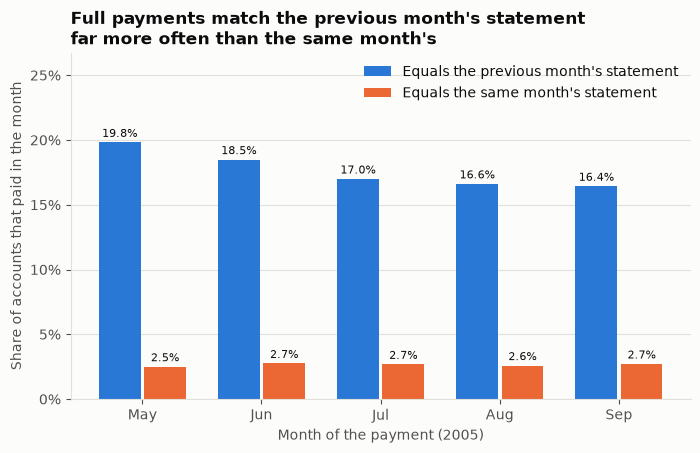

In [13]:
ordered = timing.sort_values("month", ascending=False)  # calendar order: May -> September
positions = range(len(ordered))
width = 0.38
series = [
    ("share_equals_previous_bill", "Equals the previous month's statement", plotting.BLUE),
    ("share_equals_same_month_bill", "Equals the same month's statement", plotting.ORANGE),
]

fig, ax = plt.subplots(figsize=(8, 4.5))
for (column, label, colour), offset in zip(series, [-width / 2, width / 2], strict=True):
    x = [p + offset for p in positions]
    bars = ax.bar(x, ordered[column], width=width - 0.03, color=colour, label=label)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in ordered[column]], padding=2, fontsize=8)
ax.set_xticks(list(positions), ordered["calendar_month"])
ax.set_xlabel("Month of the payment (2005)")
ax.set_ylabel("Share of accounts that paid in the month")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_ylim(0, ordered["share_equals_previous_bill"].max() * 1.35)
ax.set_title(
    "Full payments match the previous month's statement\nfar more often than the same month's"
)
plotting.save_figure(fig, "eda_payment_timing")
plt.show()

The payment equals the previous statement in 16.4% to 19.8% of paying accounts, and the same-month
statement in 2.5% to 2.7%. The column `share_equals_both` shows that nearly all of the same-month
matches are accounts whose two statements are the same amount, so they are not evidence for the
same-month reading at all.

**Check 2: every account.** Check 1 only speaks for clients who pay in full. A second check uses all
accounts. A statement is the earlier statement, minus the payment, plus new purchases and charges,
so the purchases implied by two consecutive statements and the payment between them should not be
negative. The table gives the share of accounts with negative implied purchases under each reading.

In [14]:
purchases = quality.implied_purchases(raw)
purchases.insert(1, "calendar_month", purchases["month"].map(MONTH_LABELS))
purchase_shares = [c for c in purchases.columns if c.startswith("share_")]
show(purchases.set_index("month"), percent=purchase_shares)

,calendar_month,share_negative_if_settles_previous_bill,share_negative_if_settles_same_month_bill
month,,,
2,Aug,0.4%,17.1%
3,Jul,0.4%,19.1%
4,Jun,0.4%,18.0%
5,May,0.4%,15.8%


Under the "previous statement" reading about 0.4% of accounts have negative implied purchases in
each month (refunds can explain a share of this size). Under the "same month" reading it is 15.8%
to 19.1%. Both checks agree.

**Decision (ADR-009).** `PAY_AMTk` is treated as the payment of statement `BILL_AMT{k+1}`. Payment
ratios will be built as `PAY_AMTk / BILL_AMT{k+1}`, which gives five usable months (the April
statement has no earlier statement in the file).

## 8. Apply the recoding

The only change made to the data is the fixed recoding of section 2. It is a written mapping that
does not depend on the data, so applying it before the train/test split leaks nothing.

In [15]:
data = clean.recode_undocumented_codes(raw)

unchanged = [c for c in raw.columns if c not in clean.RECODES]
assert raw[unchanged].equals(data[unchanged])
assert len(data) == len(raw)

print("Rows recoded:", quality.recoded_row_counts(raw))
for column in clean.RECODES:
    table = quality.code_counts(data, column, DOCUMENTED_CODES[column])
    show(table.set_index("value"), percent=["share"], whole=["count"])

Rows recoded: {'EDUCATION': 345, 'MARRIAGE': 54}


,count,share,documented
value,,,
1,"10,585",35.3%,True
2,"14,030",46.8%,True
3,"4,917",16.4%,True
4,468,1.6%,True


,count,share,documented
value,,,
1,"13,659",45.5%,True
2,"15,964",53.2%,True
3,377,1.3%,True


## 9. Columns available at prediction time

The model is meant to be scored at the end of September 2005 to predict default in October 2005.
The table lists each group of columns, the period it describes and how it is used.

In [16]:
groups = {
    "Limit and demographics": ["LIMIT_BAL", "AGE", "EDUCATION"],
    "Repayment status": PAY_COLS,
    "Bill amounts": BILL_COLS,
    "Payment amounts": PAYAMT_COLS,
    "Sensitive attributes": SENSITIVE_COLS,
    "Target": [TARGET],
}
period = {
    "Limit and demographics": "not dated in the file",
    "Repayment status": "Apr-Sep 2005",
    "Bill amounts": "Apr-Sep 2005",
    "Payment amounts": "Apr-Sep 2005",
    "Sensitive attributes": "not dated in the file",
    "Target": "Oct 2005",
}
rows = []
for group, group_columns in groups.items():
    is_candidate = all(c in CANDIDATE_FEATURE_COLS for c in group_columns)
    use = "candidate feature" if is_candidate else "fairness audit only (ADR-002)"
    rows.append(
        {
            "group": group,
            "columns": f"{group_columns[0]} ... {group_columns[-1]}",
            "n_columns": len(group_columns),
            "period": period[group],
            "use": "outcome" if group == "Target" else use,
        }
    )
print(f"{len(CANDIDATE_FEATURE_COLS)} candidate feature columns")
display(pd.DataFrame(rows).set_index("group"))

21 candidate feature columns


,columns,n_columns,period,use
group,,,,
Limit and demographics,LIMIT_BAL ... EDUCATION,3,not dated in the file,candidate feature
Repayment status,PAY_1 ... PAY_6,6,Apr-Sep 2005,candidate feature
Bill amounts,BILL_AMT1 ... BILL_AMT6,6,Apr-Sep 2005,candidate feature
Payment amounts,PAY_AMT1 ... PAY_AMT6,6,Apr-Sep 2005,candidate feature
Sensitive attributes,SEX ... MARRIAGE,2,not dated in the file,fairness audit only (ADR-002)
Target,DEFAULT ... DEFAULT,1,Oct 2005,outcome


That every candidate column was known before October is an **ASSUMPTION** resting on the dataset
description. The file gives no recording dates. Three caveats are recorded in ADR-009:

- `PAY_1` is the column most at risk, for the reasons in section 3.
- `LIMIT_BAL`, `AGE` and `EDUCATION` are not dated. A credit limit is something a bank adjusts in
  response to behaviour, so it could reflect a later date than September.
- `AGE` and `EDUCATION` are candidates only pending the justification required by ADR-002.

## Save the results

Every figure quoted above, in `docs/DATA.md` and in `docs/DECISIONS.md` for this phase comes from
this file.

In [17]:
metrics = quality.data_quality_report(raw)
path = save_metrics("data_quality", metrics, data_sha256)
print(f"Saved {path.relative_to(path.parents[2]).as_posix()}")

Saved reports/metrics/data_quality.json


## Summary of decisions

| Finding | Decision | Recorded in |
|---|---|---|
| Undocumented `EDUCATION` and `MARRIAGE` codes | Move to the documented "others" category | ADR-008 |
| `PAY_*` codes −2 and 0 | Keep as separate categories; meaning is an ASSUMPTION | ADR-008 |
| September status recorded on a different basis (code 1, delay codes with nothing billed) | Keep; handle in feature engineering and in the collections analysis | ADR-008 |
| Negative bills, bills over the limit | Keep; floor at zero only inside the formulas that need it | ADR-008 |
| Inactive accounts | Keep in the population | ADR-008 |
| Identical rows | Keep all rows; count twins across the split later | ADR-008 |
| Extreme amounts | Keep; no capping | ADR-008 |
| Payment timing | `PAY_AMTk` settles `BILL_AMT{k+1}` | ADR-009 |
| Columns at prediction time | Candidates precede the outcome month (ASSUMPTION); `PAY_1` gets a leakage check | ADR-009 |